# ECE1512 Project B, Part 2: DNN-Based JPEG Restoration (Colab)

Run top to bottom on a **GPU runtime**. Pipeline: clean x -> JPEG at quality Q -> y -> residual CNN -> x_hat = y + f(y).
Dataset: `data_1um_bicubic.zip` from https://huggingface.co/datasets/LeonYe/ADPPatches (downloaded automatically)

## 1. Setup

In [ ]:
import os, io, sys, json, math, random, shutil, zipfile, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import functional as TF

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > GPU, then restart.")

PyTorch: 2.14.1+cu130 | device: cuda
GPU: Tesla T4


## 2. Download the dataset from Hugging Face

Downloads `data_1um_bicubic.zip` from https://huggingface.co/datasets/LeonYe/ADPPatches directly into Colab and extracts it (no upload from your computer).

In [ ]:
from pathlib import Path
import os, sys, zipfile, subprocess

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
from huggingface_hub import hf_hub_download

WORK = Path("/content/data"); WORK.mkdir(parents=True, exist_ok=True)

zip_path = hf_hub_download(repo_id="LeonYe/ADPPatches", repo_type="dataset",
                           filename="data_1um_bicubic.zip", local_dir=str(WORK))
print("Downloaded:", zip_path)

print("Extracting...")
with zipfile.ZipFile(zip_path) as z:
    z.extractall(WORK)
# os.remove(zip_path)   # uncomment to free ~2 GB of disk

def find_data_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        if {"train", "val", "test"} <= set(dirnames):
            return Path(dirpath)

DATA_ROOT = find_data_root(WORK)
assert DATA_ROOT is not None, "No folder with train/, val/, test/ found"
print("DATA_ROOT =", DATA_ROOT)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
DIRS = {s: str(DATA_ROOT / s) for s in ["train", "val", "test"]}
for s, d in DIRS.items():
    print(s, sum(1 for p in Path(d).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS), "images")

data_1um_bicubic.zip: reconstructing file:   0%|          |  0.00B / 2.12GB            

data_1um_bicubic.zip: downloading bytes:           |  0.00B            

Downloaded: /content/data/data_1um_bicubic.zip
Extracting...
DATA_ROOT = /content/data/data_1um_bicubic
train 12616 images
val 1576 images
test 1576 images


## 2b. What is the "original" reference? (native size and file format)

The rubric measures PSNR/SSIM against the **original uncompressed images**. The cell below prints one test image's native size and file format **once**, and summarizes all test images, so the report can state exactly what the reference is. If the native images are larger than the 256x256 evaluation crop, then the reference used for every PSNR/SSIM number is the **256x256 center crop** of the original, not the full image.

In [ ]:
# Print native size + file format of one test image (header read only, no decode), then summarize all test images.
EVAL_PS = 256   # must equal CFG["eval_patch_size"] (CFG is defined in the next section)
test_paths = sorted(p for p in Path(DIRS["test"]).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)

with Image.open(test_paths[0]) as im0:
    print("Example test image :", test_paths[0].name)
    print("  native size (WxH):", im0.size, "| mode:", im0.mode, "| file format:", im0.format,
          "| file size:", f"{test_paths[0].stat().st_size/1024:.1f} KiB")

fmts, sizes = {}, {}
for p in test_paths:
    with Image.open(p) as im:
        fmts[im.format] = fmts.get(im.format, 0) + 1
        sizes[im.size] = sizes.get(im.size, 0) + 1
ws = [s[0] for s in sizes for _ in range(sizes[s])]; hs = [s[1] for s in sizes for _ in range(sizes[s])]
n_larger  = sum(c for (w, h), c in sizes.items() if w > EVAL_PS or h > EVAL_PS)
n_smaller = sum(c for (w, h), c in sizes.items() if min(w, h) < EVAL_PS)
NATIVE = dict(n_test=len(test_paths), formats=fmts, distinct_sizes=len(sizes),
              min_wh=(min(ws), min(hs)), max_wh=(max(ws), max(hs)),
              n_larger_than_crop=n_larger, n_smaller_than_crop=n_smaller,
              most_common_size=max(sizes, key=sizes.get))
print("\nAll test images:", json.dumps(NATIVE, indent=1, default=str))

if n_larger == 0 and n_smaller == 0 and set(sizes) == {(EVAL_PS, EVAL_PS)}:
    print(f"\nREFERENCE: every test image is natively {EVAL_PS}x{EVAL_PS}, so the reference is the full original image.")
else:
    print(f"\nREFERENCE: {n_larger}/{len(test_paths)} test images are larger than {EVAL_PS}x{EVAL_PS} -> PSNR/SSIM are measured against the "
          f"{EVAL_PS}x{EVAL_PS} CENTER CROP of the original, not the full image.")
    if n_smaller:
        print(f"  NOTE: {n_smaller} images have a side < {EVAL_PS}px and are bicubic-UPSAMPLED before cropping, so for those the reference is an upsampled image.")
lossy = [f for f in fmts if f in ("JPEG", "WEBP")]
if lossy:
    print(f"  WARNING: source files include lossy format(s) {lossy}; the 'original' is then not truly uncompressed (state this in the report).")
else:
    print("  Source files are lossless formats:", list(fmts), "-> the reference is uncompressed.")


Example test image : 000000_069.png_crop_2537.png
  native size (WxH): (272, 272) | mode: RGB | file format: PNG | file size: 127.2 KiB

All test images: {
 "n_test": 1576,
 "formats": {
  "PNG": 1576
 },
 "distinct_sizes": 1,
 "min_wh": [
  272,
  272
 ],
 "max_wh": [
  272,
  272
 ],
 "n_larger_than_crop": 1576,
 "n_smaller_than_crop": 0,
 "most_common_size": [
  272,
  272
 ]
}

REFERENCE: 1576/1576 test images are larger than 256x256 -> PSNR/SSIM are measured against the 256x256 CENTER CROP of the original, not the full image.
  Source files are lossless formats: ['PNG'] -> the reference is uncompressed.


## 3. Configuration

Required by the assignment: report Q = {10, 15, 20, 25, 30} at least. Training uses Q in {10,20,30,40,50}, so **15 and 25 are unseen** quality factors (tests generalization).

In [ ]:
CFG = dict(
    epochs=20,                 # final run (use 1 for a quick sanity check)
    batch_size=16,
    patch_size=256,            # training crop
    eval_patch_size=256,       # center crop used for val/test
    channels=32, depth=5,      # residual CNN size
    lr=2e-4, weight_decay=1e-4,
    train_qualities=[10, 20, 30, 40, 50],
    test_qualities=[10, 15, 20, 25, 30],
    num_workers=2,
    seed=42,
    val_subset=500,            # validate on this many val images per epoch (speed)
)
assert CFG["eval_patch_size"] == EVAL_PS, "update EVAL_PS in section 2b to match eval_patch_size"
OUT = Path("/content/runs"); (OUT / "results").mkdir(parents=True, exist_ok=True)
RESULTS = OUT / "results"

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
seed_everything(CFG["seed"])
print(json.dumps(CFG, indent=1))

{
 "epochs": 20,
 "batch_size": 16,
 "patch_size": 256,
 "eval_patch_size": 256,
 "channels": 32,
 "depth": 5,
 "lr": 0.0002,
 "weight_decay": 0.0001,
 "train_qualities": [
  10,
  20,
  30,
  40,
  50
 ],
 "test_qualities": [
  10,
  15,
  20,
  25,
  30
 ],
 "num_workers": 2,
 "seed": 42,
 "val_subset": 500
}


## 4. Dataset: online JPEG degradation

Each item: random crop (train) or center crop (val/test), optional flips (train), then a JPEG round trip with **RGB 4:4:4 subsampling, `optimize=False`** at quality Q. The exact encoded byte count gives the file bits-per-pixel.

**BPP definition:** `bpp = 8 * (JPEG file bytes) / (H * W)` of the 256x256 crop, counting the full encoded file (headers and tables included). The restoration CNN runs *after* JPEG decoding and never touches the bitstream.

train/val(subset) sizes: 12616 500


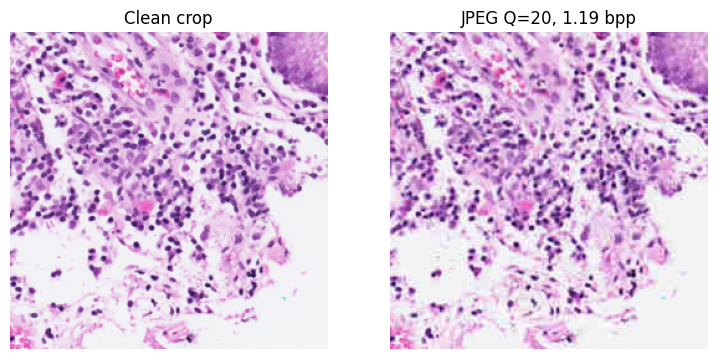

In [ ]:
def jpeg_compress_pil(img, quality, return_size=False):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=int(quality), subsampling=0, optimize=False)
    nbytes = buf.tell()
    buf.seek(0)
    with Image.open(buf) as dec:
        out = dec.convert("RGB")
    return (out, nbytes) if return_size else out


class JPEGRestorationDataset(Dataset):
    """Returns (degraded, clean, quality, bpp); tensors [3,H,W] in [0,1]."""
    def __init__(self, root, patch_size=256, qualities=(10, 20, 30, 40), train=True):
        self.paths = sorted(p for p in Path(root).rglob("*")
                            if p.is_file() and p.suffix.lower() in IMG_EXTS)
        if not self.paths:
            raise RuntimeError(f"No images in {root}")
        self.patch_size, self.train = int(patch_size), train
        self.qualities = tuple(int(q) for q in qualities)

    def __len__(self): return len(self.paths)

    def _crop(self, img):
        w, h = img.size; ps = self.patch_size
        if min(w, h) < ps:                         # upsample undersized images
            s = ps / min(w, h)
            img = img.resize((round(w * s), round(h * s)), Image.BICUBIC); w, h = img.size
        if self.train:
            l, t = random.randint(0, w - ps), random.randint(0, h - ps)
        else:
            l, t = (w - ps) // 2, (h - ps) // 2
        return img.crop((l, t, l + ps, t + ps))

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            clean = im.convert("RGB")
        clean = self._crop(clean)
        if self.train:
            if random.random() < 0.5: clean = TF.hflip(clean)
            if random.random() < 0.5: clean = TF.vflip(clean)
            q = random.choice(self.qualities)
        else:
            q = self.qualities[idx % len(self.qualities)]
        deg, nbytes = jpeg_compress_pil(clean, q, return_size=True)
        bpp = 8 * nbytes / (clean.width * clean.height)
        return TF.to_tensor(deg), TF.to_tensor(clean), q, float(bpp)


train_set = JPEGRestorationDataset(DIRS["train"], CFG["patch_size"], CFG["train_qualities"], train=True)
val_full  = JPEGRestorationDataset(DIRS["val"],   CFG["eval_patch_size"], CFG["train_qualities"], train=False)
rng = random.Random(0)
val_idx = rng.sample(range(len(val_full)), min(CFG["val_subset"], len(val_full)))
val_set = Subset(val_full, val_idx)
print("train/val(subset) sizes:", len(train_set), len(val_set))

d, c, q, bpp = train_set[0]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(c.permute(1, 2, 0)); ax[0].set_title("Clean crop")
ax[1].imshow(d.permute(1, 2, 0)); ax[1].set_title(f"JPEG Q={q}, {bpp:.2f} bpp")
for a in ax: a.axis("off")
plt.show()

## 5. Image quality metrics (from scratch)

* **PSNR** (per image, RGB, data range 1): $\mathrm{PSNR}=10\log_{10}\!\big(1/\mathrm{MSE}\big)$.
* **SSIM**: Gaussian window (11x11, sigma 1.5), $C_1=(0.01)^2$, $C_2=(0.03)^2$, computed per RGB channel with "valid" convolution, then averaged:
$$\mathrm{SSIM}=\frac{(2\mu_x\mu_y+C_1)(2\sigma_{xy}+C_2)}{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)}.$$

In [ ]:
def psnr(pred, target, data_range=1.0):
    """One PSNR value per image for [B,C,H,W] tensors."""
    mse = torch.mean((pred.float() - target.float()) ** 2, dim=(1, 2, 3))
    return 10.0 * torch.log10((data_range ** 2) / torch.clamp(mse, min=1e-10))


def _gaussian_window(size=11, sigma=1.5, channels=3, device=None, dtype=torch.float32):
    coords = torch.arange(size, device=device, dtype=dtype) - size // 2
    g = torch.exp(-coords ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    w2d = g[:, None] * g[None, :]
    return w2d.expand(channels, 1, size, size).contiguous()


def ssim_per_image(pred, target, data_range=1.0, size=11, sigma=1.5):
    pred, target = pred.float(), target.float()
    C = pred.shape[1]
    w = _gaussian_window(size, sigma, C, pred.device, pred.dtype)
    c1, c2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    conv = lambda x: F.conv2d(x, w, groups=C)
    mu_x, mu_y = conv(pred), conv(target)
    sxx = conv(pred * pred) - mu_x ** 2
    syy = conv(target * target) - mu_y ** 2
    sxy = conv(pred * target) - mu_x * mu_y
    num = (2 * mu_x * mu_y + c1) * (2 * sxy + c2)
    den = (mu_x ** 2 + mu_y ** 2 + c1) * (sxx + syy + c2)
    return (num / den).mean(dim=(1, 2, 3))


def batch_ssim(pred, target):
    """Mean RGB SSIM over a batch."""
    return ssim_per_image(pred, target).mean()

## 6. Residual CNN and loss

In [ ]:
class ResidualRestorationCNN(nn.Module):
    """Conv(3->C)+ReLU, (depth-2) x [Conv(C->C)+ReLU], Conv(C->3); output = clamp(y + f(y), 0, 1)."""
    def __init__(self, channels=32, depth=5):
        super().__init__()
        layers = [nn.Conv2d(3, channels, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(channels, 3, 3, padding=1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return torch.clamp(x + self.net(x), 0.0, 1.0)

def count_parameters(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def criterion(pred, target):
    """Spatial L1 loss: mean |x_hat - x|."""
    return F.l1_loss(pred, target)

m = ResidualRestorationCNN(CFG["channels"], CFG["depth"]); print(m)
print(f"Trainable parameters: {count_parameters(m):,}"); del m

ResidualRestorationCNN(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)
Trainable parameters: 29,507


## 7. Training

AdamW, cosine LR, L1 loss; `best.pt` = best validation restored PSNR.

29,507 parameters


epoch 1/20:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 1: L1=0.0226 | val PSNR 29.67 -> 31.20 dB | SSIM 0.8472 -> 0.8842


epoch 2/20:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 2: L1=0.0206 | val PSNR 29.67 -> 31.40 dB | SSIM 0.8472 -> 0.8879


epoch 3/20:   0%|          | 0/788 [00:00<?, ?it/s]

... (36 outputs left out)

epoch 19/20:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 19: L1=0.0192 | val PSNR 29.67 -> 31.76 dB | SSIM 0.8472 -> 0.8953


epoch 20/20:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 20: L1=0.0193 | val PSNR 29.67 -> 31.76 dB | SSIM 0.8472 -> 0.8952
Training time: 31.6 min


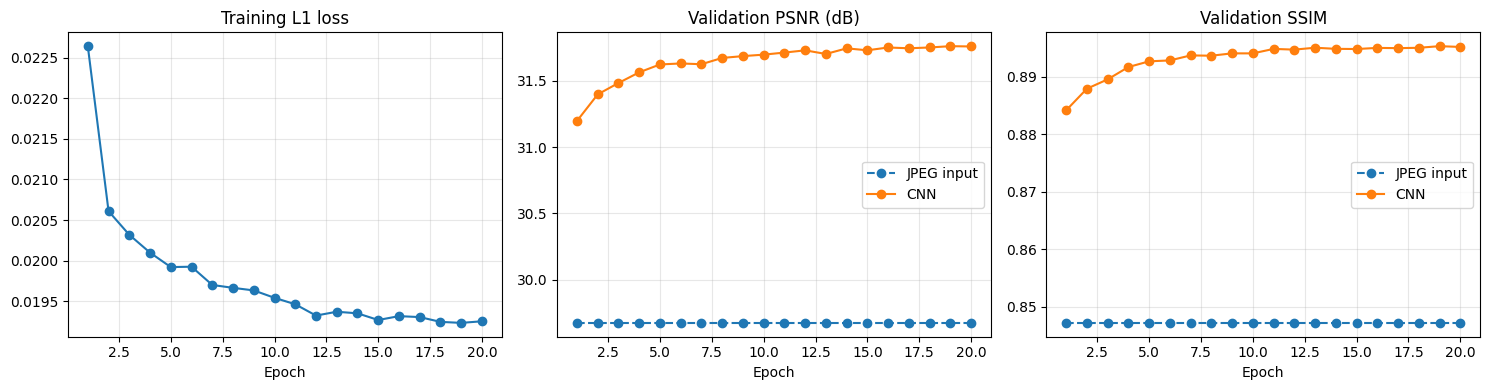

In [ ]:
@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    t = dict(input_psnr=0., restored_psnr=0., input_ssim=0., restored_ssim=0.); n_img = 0
    for deg, clean, _, _ in loader:
        deg, clean = deg.to(device), clean.to(device)
        res = model(deg); n = clean.shape[0]
        t["input_psnr"] += psnr(deg, clean).sum().item()
        t["restored_psnr"] += psnr(res, clean).sum().item()
        t["input_ssim"] += ssim_per_image(deg, clean).sum().item()
        t["restored_ssim"] += ssim_per_image(res, clean).sum().item()
        n_img += n
    return {k: v / n_img for k, v in t.items()}


def train_one_batch(model, degraded, clean, criterion, optimizer, scaler, device):
    degraded = degraded.to(device, non_blocking=True)
    clean = clean.to(device, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
        restored = model(degraded)
        loss = criterion(restored, clean)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return float(loss.detach().item())


def train_experiment(cfg, out_dir, device):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "config.json").write_text(json.dumps(cfg, indent=2))
    seed_everything(cfg["seed"])
    g = torch.Generator().manual_seed(cfg["seed"])
    common = dict(batch_size=cfg["batch_size"], num_workers=cfg["num_workers"],
                  pin_memory=(device.type == "cuda"))
    train_loader = DataLoader(train_set, shuffle=True, generator=g, drop_last=True, **common)
    val_loader = DataLoader(val_set, shuffle=False, **common)

    model = ResidualRestorationCNN(cfg["channels"], cfg["depth"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    print(f"{count_parameters(model):,} parameters")

    best, history = -float("inf"), []
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); tot, cnt = 0.0, 0; lr_now = opt.param_groups[0]["lr"]
        bar = tqdm(train_loader, desc=f"epoch {epoch}/{cfg['epochs']}")
        for deg, clean, _, _ in bar:
            loss = train_one_batch(model, deg, clean, criterion, opt, scaler, device)
            tot += loss * clean.shape[0]; cnt += clean.shape[0]
            bar.set_postfix(loss=f"{loss:.4f}")
        sched.step()
        m = validate(model, val_loader, device)
        m.update(train_loss=tot / cnt, epoch=epoch, lr=lr_now); history.append(m)
        ckpt = {"model": model.state_dict(), "args": cfg, "epoch": epoch, "validation": m}
        torch.save(ckpt, out_dir / "last.pt")
        if m["restored_psnr"] > best:
            best = m["restored_psnr"]; torch.save(ckpt, out_dir / "best.pt")
        (out_dir / "history.json").write_text(json.dumps(history, indent=2))
        print(f"Epoch {epoch}: L1={m['train_loss']:.4f} | val PSNR {m['input_psnr']:.2f} -> "
              f"{m['restored_psnr']:.2f} dB | SSIM {m['input_ssim']:.4f} -> {m['restored_ssim']:.4f}")
    return pd.DataFrame(history)


RUN_DIR = OUT / "spatial_only"
t0 = time.time()
history = train_experiment(CFG, RUN_DIR, DEVICE)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history.epoch, history.train_loss, "o-"); ax[0].set_title("Training L1 loss")
ax[1].plot(history.epoch, history.input_psnr, "o--", label="JPEG input")
ax[1].plot(history.epoch, history.restored_psnr, "o-", label="CNN"); ax[1].set_title("Validation PSNR (dB)")
ax[2].plot(history.epoch, history.input_ssim, "o--", label="JPEG input")
ax[2].plot(history.epoch, history.restored_ssim, "o-", label="CNN"); ax[2].set_title("Validation SSIM")
for a in ax: a.set_xlabel("Epoch"); a.grid(alpha=.3)
ax[1].legend(); ax[2].legend(); fig.tight_layout()
fig.savefig(RESULTS / "training_curves.png", dpi=160); plt.show()

## 8. Test evaluation: JPEG vs. restored at Q = 10, 15, 20, 25, 30

Same center 256x256 crop (see section 2b for what the original reference is) and the **same JPEG bytes** for both methods. Q = 15 and 25 were not used in training.

**Measured BPP:** each JPEG crop is encoded once and its exact byte count gives the file bpp. The CNN is a post-decoder: it consumes the decoded JPEG pixels `y`, so the restored images are produced from the identical bitstream. Their BPP is therefore **identical** to the JPEG BPP at every Q (the CNN adds no bits and removes none); the gain in PSNR/SSIM is at no extra rate.

In [ ]:
def load_best(path, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    c = ck["args"]
    model = ResidualRestorationCNN(c["channels"], c["depth"]).to(device)
    model.load_state_dict(ck["model"]); model.eval()
    return model, ck

model, ckpt = load_best(RUN_DIR / "best.pt", DEVICE)
print("Loaded best checkpoint from epoch", ckpt["epoch"])

@torch.no_grad()
def evaluate_all(model, qualities, device):
    rows = []
    for q in tqdm(qualities, desc="Test Q"):
        ds = JPEGRestorationDataset(DIRS["test"], CFG["eval_patch_size"], [q], train=False)
        loader = DataLoader(ds, batch_size=32, shuffle=False, num_workers=CFG["num_workers"])
        s = dict(jp=0., cp=0., js=0., cs=0., bpp=0.); n_img = 0
        for deg, clean, _, bpp in loader:
            deg, clean = deg.to(device), clean.to(device)
            res = model(deg)
            s["bpp"] += bpp.sum().item()          # measured JPEG file bits per pixel of each crop
            s["jp"] += psnr(deg, clean).sum().item();  s["cp"] += psnr(res, clean).sum().item()
            s["js"] += ssim_per_image(deg, clean).sum().item(); s["cs"] += ssim_per_image(res, clean).sum().item()
            n_img += clean.shape[0]
        s = {k: v / n_img for k, v in s.items()}
        rows.append({"Q": q, "Images": n_img,
                     "JPEG BPP": s["bpp"], "CNN BPP (same bytes)": s["bpp"],
                     "JPEG PSNR": s["jp"], "CNN PSNR": s["cp"], "PSNR gain (dB)": s["cp"] - s["jp"],
                     "JPEG SSIM": s["js"], "CNN SSIM": s["cs"], "SSIM gain": s["cs"] - s["js"]})
    return pd.DataFrame(rows)

results = evaluate_all(model, CFG["test_qualities"], DEVICE)
# Restored images are decoded from the SAME JPEG bytes, so their BPP must equal the JPEG BPP exactly.
assert (results["JPEG BPP"] == results["CNN BPP (same bytes)"]).all()
results.to_csv(RESULTS / "test_metrics.csv", index=False)
(RESULTS / "reference_info.json").write_text(json.dumps(
    dict(reference=f"{CFG['eval_patch_size']}x{CFG['eval_patch_size']} center crop of the original", native=NATIVE,
         bpp_note="CNN BPP equals JPEG BPP: restoration is applied after JPEG decoding, bitstream unchanged"), indent=2, default=str))
display(results.round(4))
print(f"Reference for all PSNR/SSIM: {CFG['eval_patch_size']}x{CFG['eval_patch_size']} center crop of the original "
      f"(native sizes: min {NATIVE['min_wh']}, max {NATIVE['max_wh']}; formats {NATIVE['formats']}).")
print("BPP: restored images share the JPEG bytes, so CNN BPP == JPEG BPP at every Q (CNN adds 0 bits).")

Loaded best checkpoint from epoch 19


Test Q:   0%|          | 0/5 [00:00<?, ?it/s]

,Q,Images,JPEG BPP,CNN BPP (same bytes),JPEG PSNR,CNN PSNR,PSNR gain (dB),JPEG SSIM,CNN SSIM,SSIM gain
0,10,1576,0.6002,0.6002,26.3657,28.5308,2.1651,0.7708,0.8387,0.0679
1,15,1576,0.7465,0.7465,27.8539,30.1707,2.3168,0.8122,0.8749,0.0627
2,20,1576,0.8787,0.8787,28.8730,31.2090,2.3360,0.8378,0.8941,0.0563
3,25,1576,1.0040,1.0040,29.6422,31.9337,2.2915,0.8553,0.9062,0.0509
4,30,1576,1.1187,1.1187,30.2382,32.4693,2.2311,0.8681,0.9142,0.0461


Reference for all PSNR/SSIM: 256x256 center crop of the original (native sizes: min (272, 272), max (272, 272); formats {'PNG': 1576}).
BPP: restored images share the JPEG bytes, so CNN BPP == JPEG BPP at every Q (CNN adds 0 bits).


## 9. PSNR and SSIM vs. JPEG quality

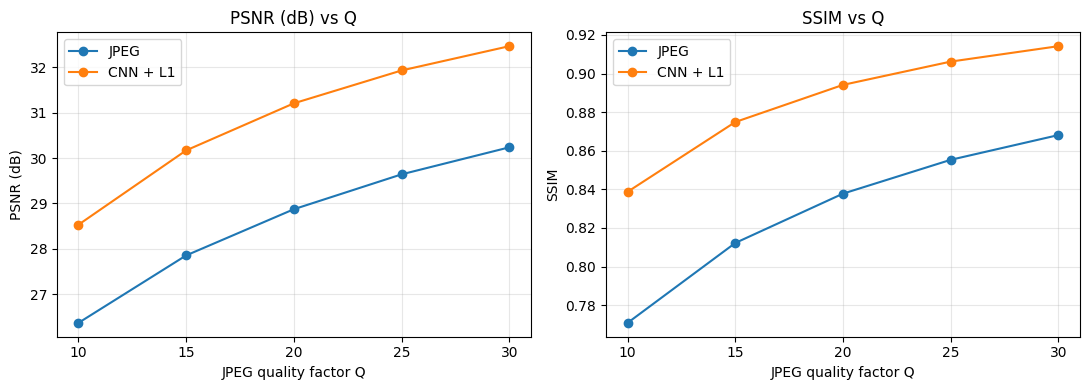

In [ ]:
r = results.sort_values("Q")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (jc, cc, yl) in zip(ax, [("JPEG PSNR", "CNN PSNR", "PSNR (dB)"), ("JPEG SSIM", "CNN SSIM", "SSIM")]):
    a.plot(r.Q, r[jc], "o-", label="JPEG"); a.plot(r.Q, r[cc], "o-", label="CNN + L1")
    a.set(xlabel="JPEG quality factor Q", ylabel=yl, title=yl + " vs Q"); a.set_xticks(r.Q); a.grid(alpha=.3); a.legend()
fig.tight_layout(); fig.savefig(RESULTS / "quality_curves.png", dpi=160); plt.show()

## 10. Qualitative examples

Change `EXAMPLE_INDICES` to pick images with edges, texture and smooth regions for your report.

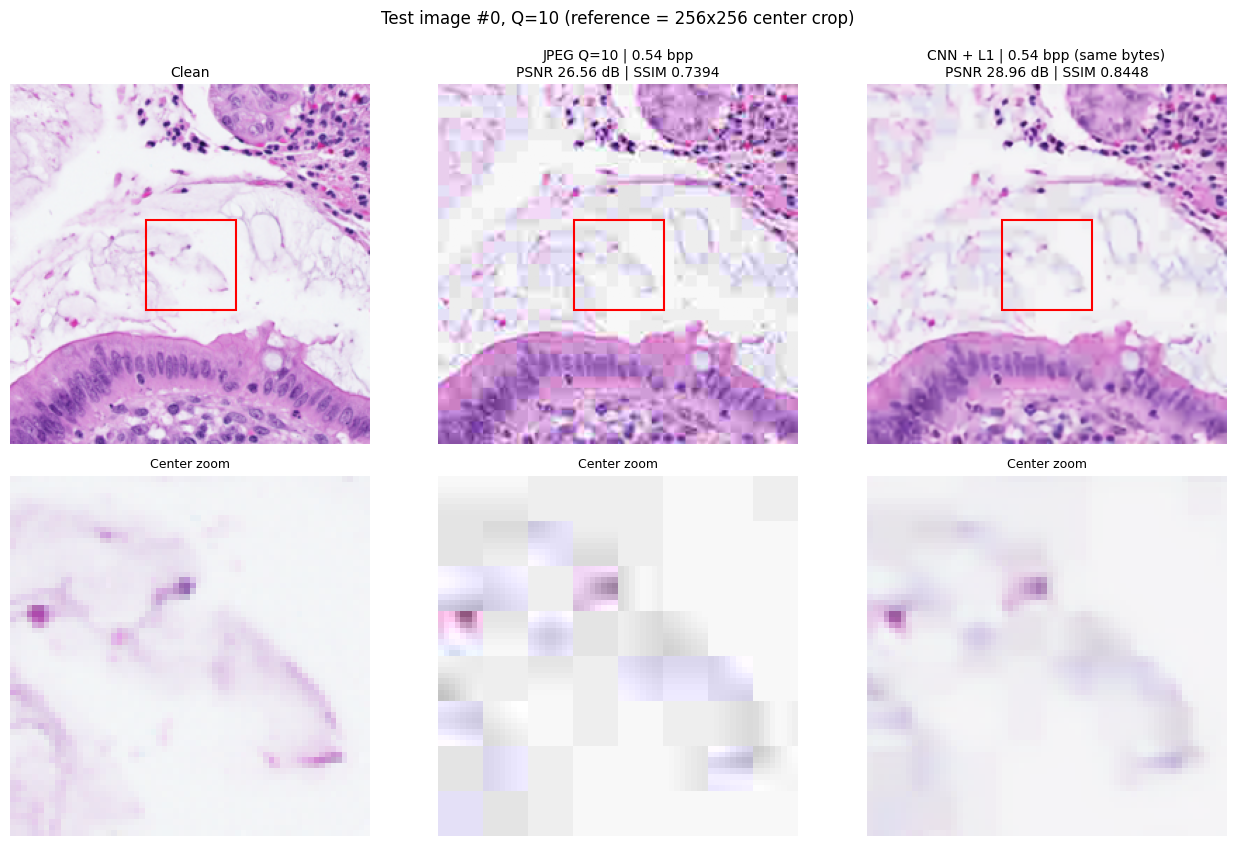

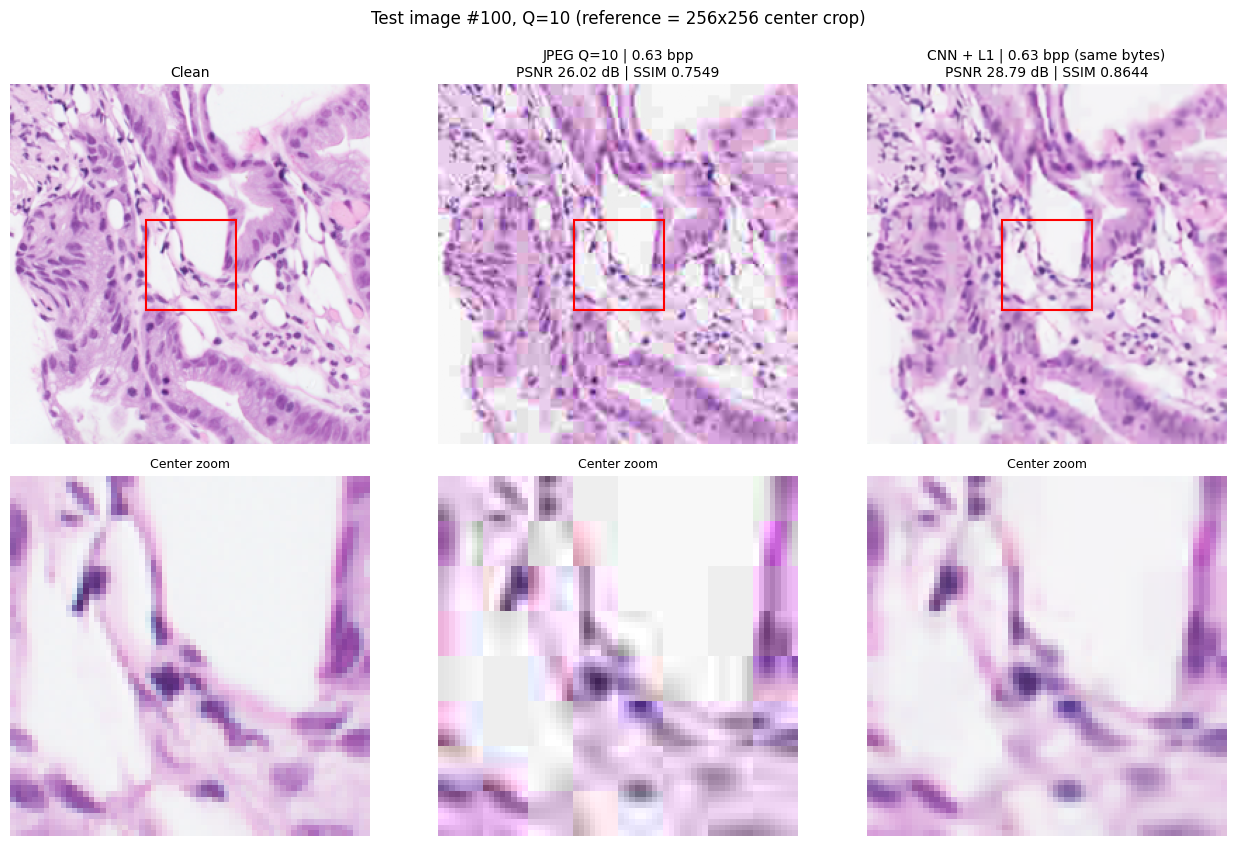

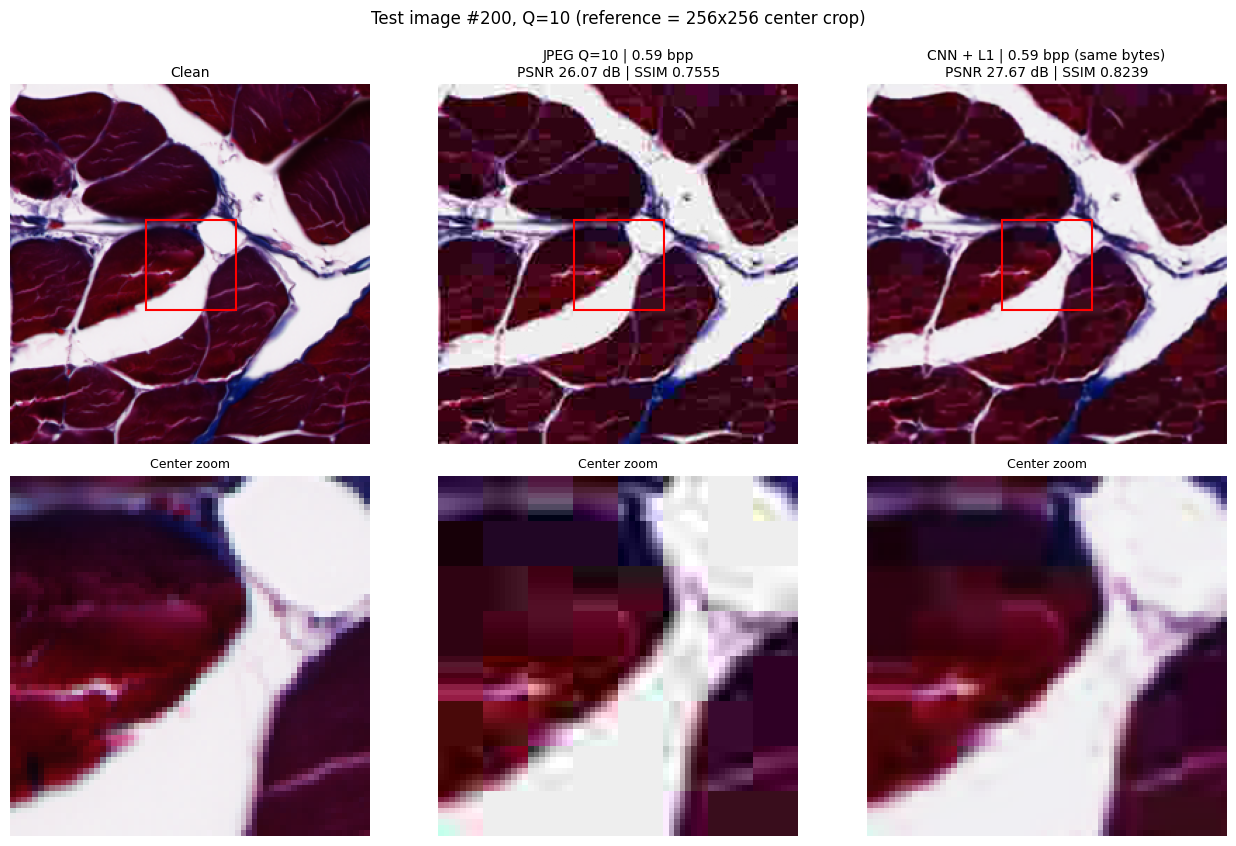

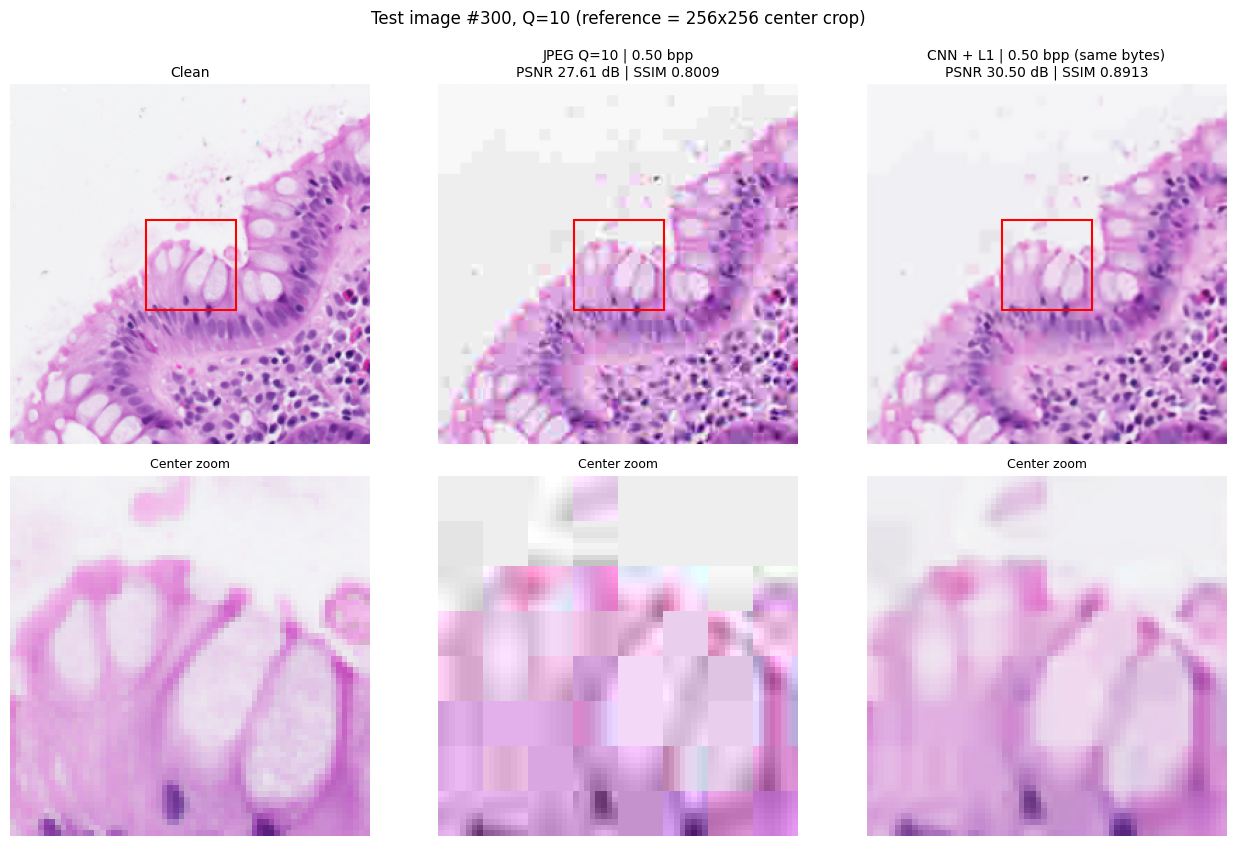

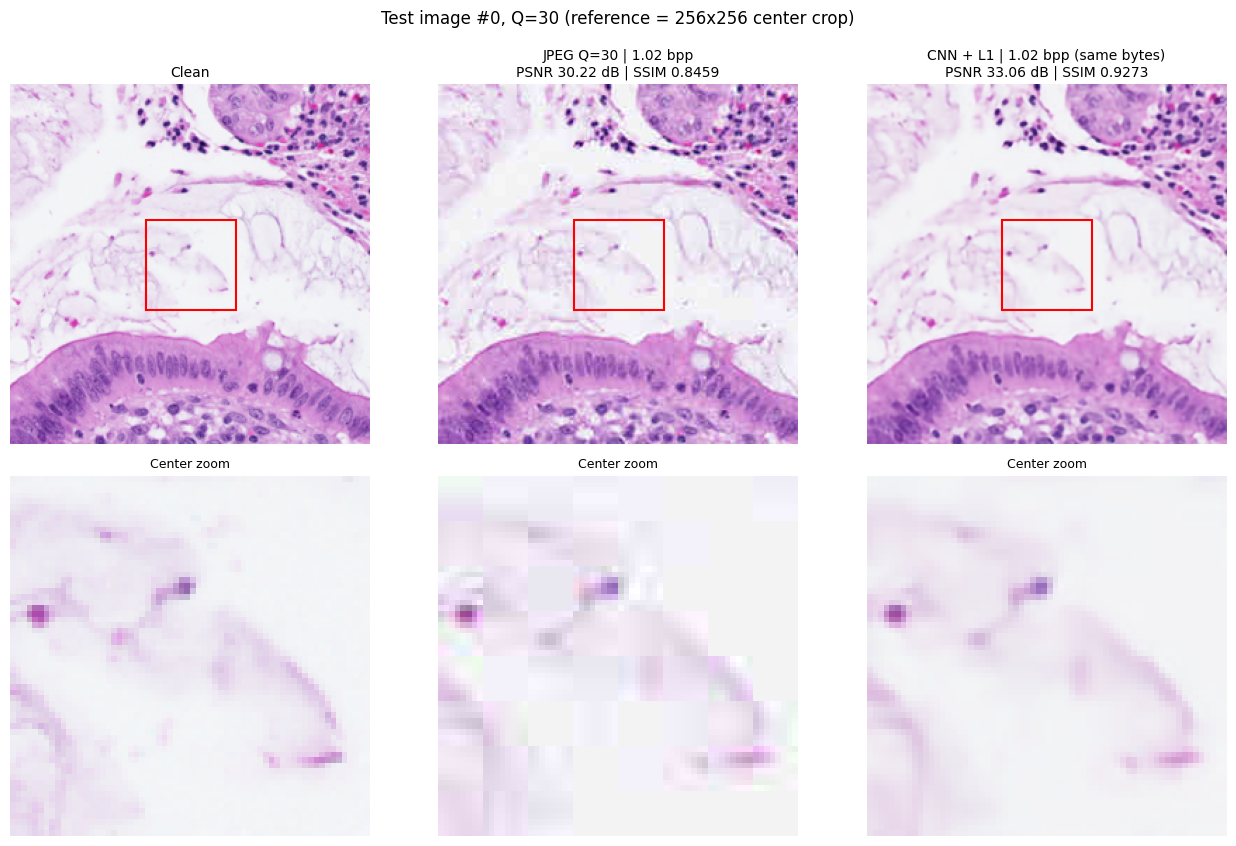

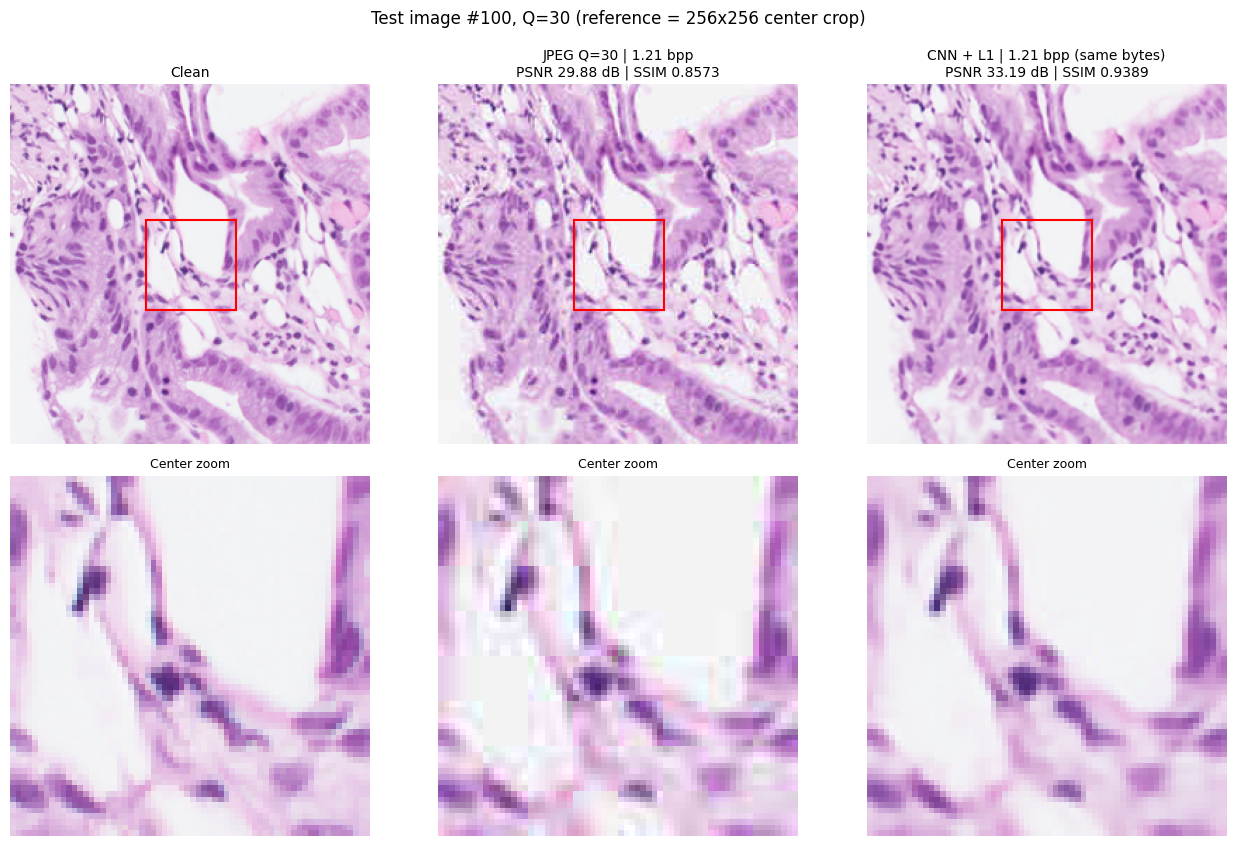

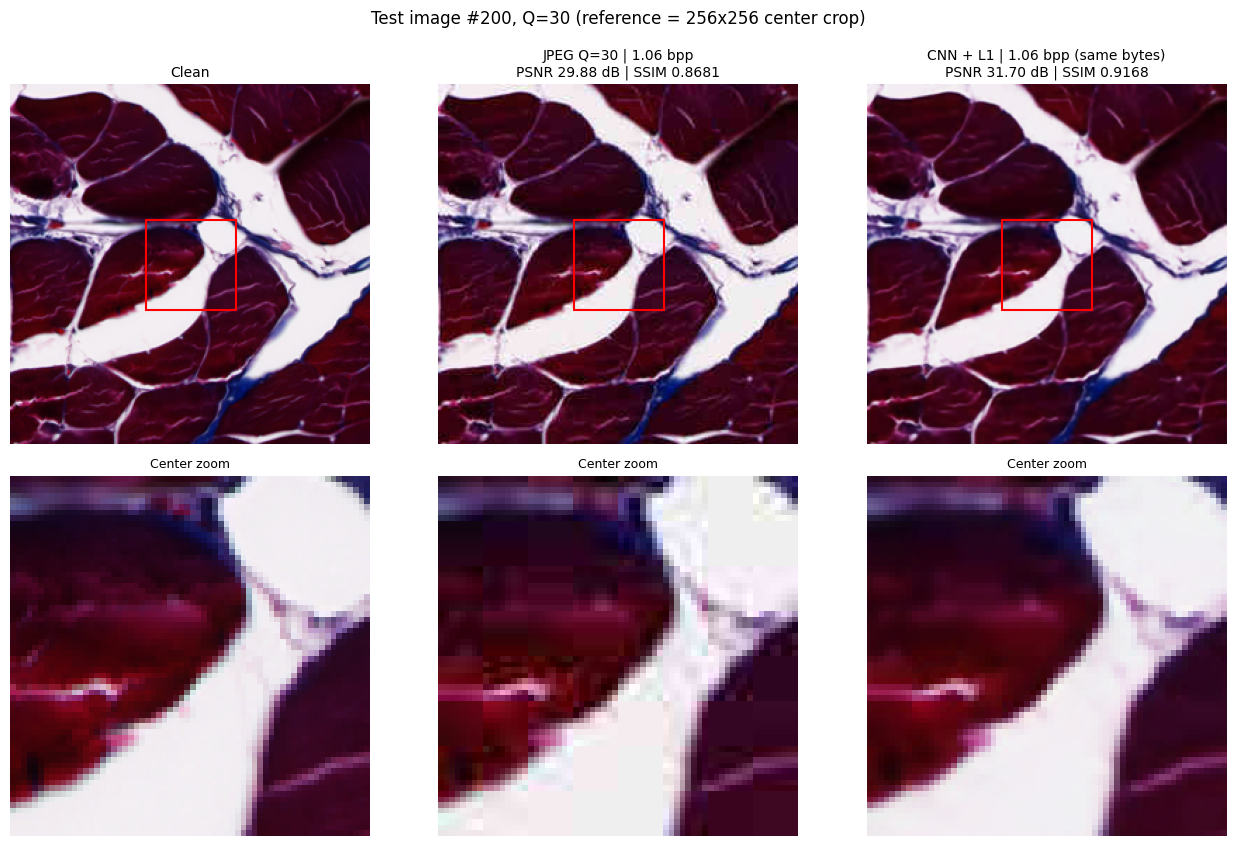

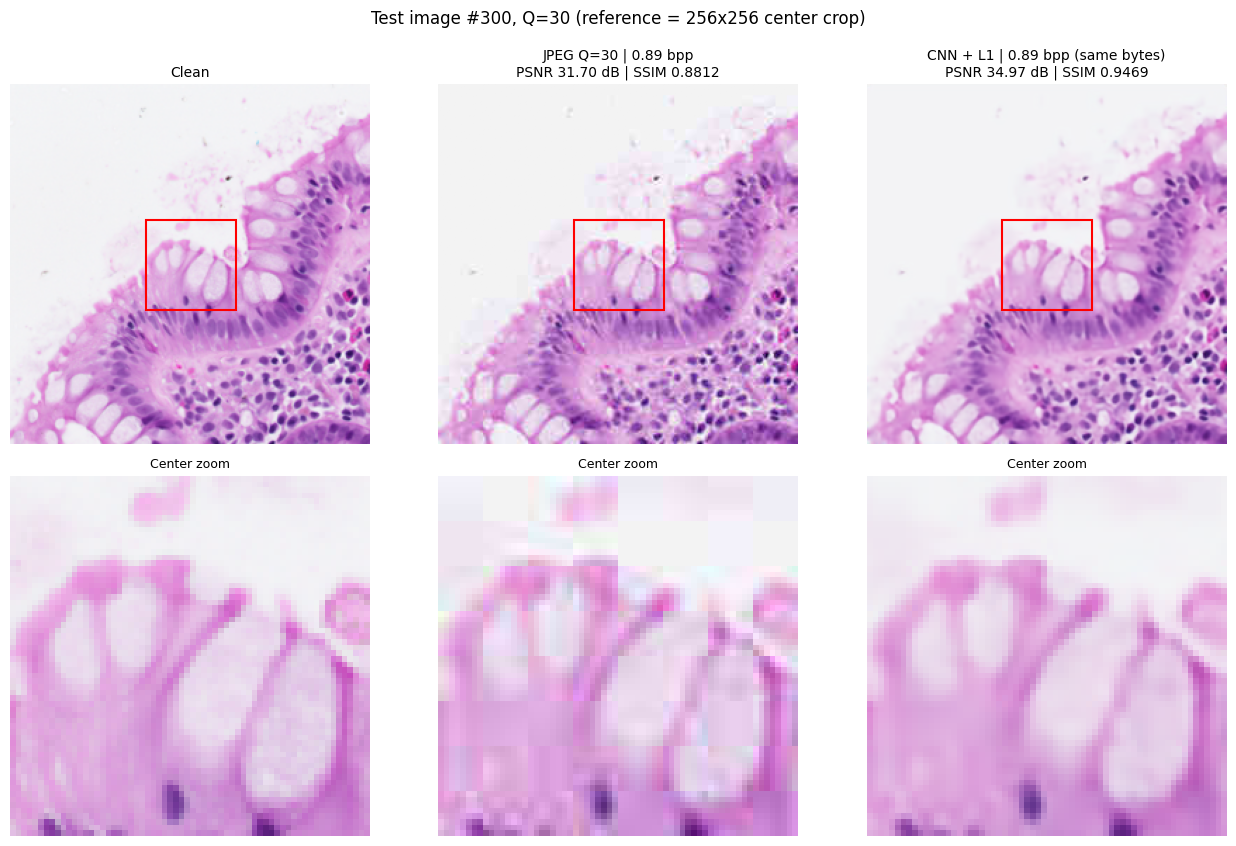

In [ ]:
EXAMPLE_INDICES = [0, 100, 200, 300]     # test-image indices
VISUAL_QUALITIES = [10, 30]

@torch.no_grad()
def show_example(model, idx, q, zoom=64):
    ds = JPEGRestorationDataset(DIRS["test"], CFG["eval_patch_size"], [q], train=False)
    deg, clean, _, bpp = ds[idx]
    res = model(deg[None].to(DEVICE)).cpu()
    p_j, p_r = psnr(deg[None], clean[None]).item(), psnr(res, clean[None]).item()
    s_j, s_r = batch_ssim(deg[None], clean[None]).item(), batch_ssim(res, clean[None]).item()
    H = clean.shape[1]; a, b = H // 2 - zoom // 2, H // 2 + zoom // 2
    imgs = [("Clean", clean, None), (f"JPEG Q={q} | {bpp:.2f} bpp", deg, (p_j, s_j)), (f"CNN + L1 | {bpp:.2f} bpp (same bytes)", res[0], (p_r, s_r))]
    fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
    for j, (title, im, ms) in enumerate(imgs):
        ax[0, j].imshow(im.permute(1, 2, 0).clamp(0, 1))
        ax[0, j].set_title(title + (f"\nPSNR {ms[0]:.2f} dB | SSIM {ms[1]:.4f}" if ms else ""), fontsize=10)
        ax[0, j].add_patch(plt.Rectangle((a, a), zoom, zoom, fill=False, ec="red", lw=1.5))
        ax[1, j].imshow(im[:, a:b, a:b].permute(1, 2, 0).clamp(0, 1), interpolation="nearest")
        ax[1, j].set_title("Center zoom", fontsize=9)
    for x in ax.ravel(): x.axis("off")
    fig.suptitle(f"Test image #{idx}, Q={q} (reference = {CFG['eval_patch_size']}x{CFG['eval_patch_size']} center crop)", y=0.99); fig.tight_layout()
    fig.savefig(RESULTS / f"qual_img{idx}_Q{q}.png", dpi=150); plt.show()

for q in VISUAL_QUALITIES:
    for idx in EXAMPLE_INDICES:
        show_example(model, idx, q)

## 11. Save and download the results

Run this after all cells above. It packages everything needed for the report and the GitHub repo into one zip and downloads it:
`runs/results/` (test metrics CSV, training and quality curves, qualitative figures), `runs/spatial_only/` (`config.json`, `history.json`, best checkpoint) and a small `part2_run_info.json` (seed, config, versions).
Colab deletes `/content` when the session ends, so download before closing. Set `SAVE_TO_DRIVE = True` to also keep a copy in Google Drive.

In [ ]:
import zipfile, shutil, json, torch
from pathlib import Path

INCLUDE_BEST_CKPT = True     # runs/spatial_only/best.pt (small)
INCLUDE_LAST_CKPT = False    # runs/spatial_only/last.pt
SAVE_TO_DRIVE = False        # True: also copy the zip to Google Drive
DRIVE_DIR = "/content/drive/MyDrive/ECE1512_ProjectB_Part2"

try:
    import PIL; pillow_version = PIL.__version__
except Exception:
    pillow_version = None

_ck = globals().get("ckpt")
run_info = dict(
    part="2", seed=CFG["seed"], config=CFG, device=str(DEVICE),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    torch=torch.__version__, pillow=pillow_version,
    data_root=str(globals().get("DATA_ROOT", "")),
    jpeg_settings="Pillow JPEG, RGB 4:4:4 (subsampling=0), optimize=False",
    best_checkpoint_epoch=(_ck["epoch"] if isinstance(_ck, dict) and "epoch" in _ck else None),
)
(RESULTS / "part2_run_info.json").write_text(json.dumps(run_info, indent=2, default=str))

to_pack = [p for p in sorted(RESULTS.rglob("*")) if p.is_file()]
for name in ["config.json", "history.json"] + (["best.pt"] if INCLUDE_BEST_CKPT else []) + (["last.pt"] if INCLUDE_LAST_CKPT else []):
    p = RUN_DIR / name
    if p.exists(): to_pack.append(p)
    else: print("WARNING: missing", p)
if not any(p.suffix == ".png" for p in to_pack) or not (RESULTS / "test_metrics.csv").exists():
    print("WARNING: figures or test_metrics.csv are missing. Run the evaluation, plot and qualitative cells first.")

ZIP_PATH = Path("/content/part2_results.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for p in to_pack:
        z.write(p, Path("part2_results") / p.relative_to(OUT))
print(f"Saved {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1e6:.2f} MB) containing {len(to_pack)} files:")
for p in to_pack:
    print(f"  {str(p.relative_to(OUT)):45s} {p.stat().st_size / 1e3:9.1f} kB")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    Path(DRIVE_DIR).mkdir(parents=True, exist_ok=True)
    shutil.copy(ZIP_PATH, DRIVE_DIR)
    print("Copied to Drive:", DRIVE_DIR)

try:
    from google.colab import files as colab_files
    colab_files.download(str(ZIP_PATH))
except ImportError:
    print("Not running in Colab; the zip is at", ZIP_PATH)

Saved /content/part2_results.zip (8.95 MB) containing 16 files:
  results/part2_run_info.json                         0.7 kB
  results/qual_img0_Q10.png                        1021.1 kB
  results/qual_img0_Q30.png                        1147.1 kB
  results/qual_img100_Q10.png                      1177.1 kB
  results/qual_img100_Q30.png                      1300.6 kB
  results/qual_img200_Q10.png                      1076.4 kB
  results/qual_img200_Q30.png                      1188.9 kB
  results/qual_img300_Q10.png                       880.1 kB
  results/qual_img300_Q30.png                       978.2 kB
  results/quality_curves.png                         83.3 kB
  results/reference_info.json                         0.5 kB
  results/test_metrics.csv                            0.9 kB
  results/training_curves.png                        87.6 kB
  spatial_only/config.json                            0.3 kB
  spatial_only/history.json                           5.1 kB
  spatial_only/best.p

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>